# SEM gradients · backends and memory strategies

`PropSEM` is differentiable: give it models that require grad, build a loss from
the record, call `.backward()`, and the gradients come back on the grid. This
notebook does that for an elastic model and then looks at the options that
decide how the backward pass is computed:

1. **Three elastic gradients** — `vp`, `vs` and `rho` from one multi-shot call
2. **Memory strategies** — `Full()`, `BoundarySaving()` and `Ckpt(chunks=...)` on
   `impl='c'` and eager: time and peak memory
3. **Smaller rings** — boundary saving of the band's first element layer, and in
   lower precision
4. **A velocity-stress class** — the same three gradients with `ElasticVSSEM2DDeformed`
5. **What to use when**

About two minutes on a GPU.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.propagator import Full, BoundarySaving, Ckpt
from sweep.sem import PropSEM
from sweep.sem.equations import ElasticSEM2DDeformed
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## 1. Three elastic gradients

A homogeneous background with three small Gaussian anomalies, one in each
parameter: `vp` on the left, `vs` in the middle, `rho` on the right. The observed
data come from that model; the gradients are taken at the background, with ten
explosive surface shots in one call. All sides absorb, so no surface waves
dominate the data.

In [2]:
dh, n_order, f0, dt, nt = 10.0, 4, 8.0, 0.8e-3, 1500
shape = (97, 193)                                     # 960 m x 1920 m
zz, xx = np.meshgrid(np.arange(shape[0]), np.arange(shape[1]), indexing='ij')
def blob(ix, iz, r=8.0):
    return np.exp(-((xx - ix) ** 2 + (zz - iz) ** 2) / r ** 2).astype(np.float32)

vp0, vs0, rho0 = 2000.0, 1150.0, 2000.0
vp_true  = vp0  * (1 + 0.1 * blob(48, 48))
vs_true  = vs0  * (1 + 0.1 * blob(96, 48))
rho_true = rho0 * (1 + 0.1 * blob(144, 48))
true = [torch.tensor(m, device=device) for m in (vp_true, vs_true, rho_true)]

wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
sx = np.linspace(8, 184, 10).astype(int)
sources = np.stack([sx, np.full_like(sx, 4)], axis=1)            # 10 shots
rx = np.arange(0, shape[1], 2)
receivers = np.stack([rx, np.full_like(rx, 4)], axis=1)[None]    # one spread
impl = 'c' if device == 'cuda' else 'eager'

def make_solver(impl, memory):
    return PropSEM(ElasticSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                   abcn=20, f_dominant=f0, source_type=['sxx', 'szz'],
                   receiver_type=['vx', 'vz'], impl=impl, memory=memory, device=device)

with torch.no_grad():
    observed = make_solver(impl, Full())(wavelet, sources, receivers, models=true)
print('observed', tuple(observed.shape))

observed (10, 1500, 97, 2)


A unit source gives records of order 1e-12 here, and a loss of their squares is
small enough to underflow in single precision. The wave equation is linear in the
source, so we scale the wavelet once to give records of order one, and the
observed data with it:

In [3]:
scale = 1.0 / float(observed.pow(2).mean().sqrt())
wavelet = wavelet * scale
observed = observed * scale
print('wavelet scale %.2e' % scale)

wavelet scale 1.96e+13


The gradient call: models are leaf tensors with `requires_grad=True`, the loss is
an ordinary PyTorch expression, and `.backward()` fills `.grad`. A model tensor
shared by all shots receives the **sum** of the per-shot gradients, as autograd
gives a tensor reused across a loop.

loss 3.628e+01


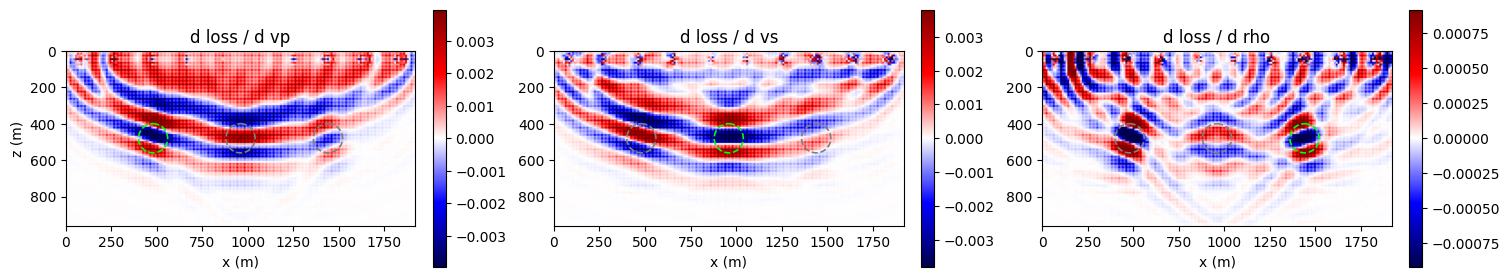

In [4]:
def gradient(solver, src=sources, obs=None):
    obs = observed if obs is None else obs
    models = [torch.full(shape, v, device=device, requires_grad=True)
              for v in (vp0, vs0, rho0)]
    pred = solver(wavelet, src, receivers, models=models)
    loss = 0.5 * (pred - obs).pow(2).sum()
    loss.backward()
    return loss.item(), [m.grad.detach().clone() for m in models]


def show(grads, label=''):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.3), constrained_layout=True)
    for ax, g, name in zip(axes, grads, ['vp', 'vs', 'rho']):
        g = g.cpu().numpy()
        lim = np.percentile(np.abs(g[12:][g[12:] != 0]), 98)     # below the acquisition rows
        im = ax.imshow(g, cmap='seismic', vmin=-lim, vmax=lim,
                       extent=[0, (shape[1] - 1) * dh, (shape[0] - 1) * dh, 0])
        for ix, c in zip((48, 96, 144), ('vp', 'vs', 'rho')):
            ax.add_patch(plt.Circle((ix * dh, 480), 80, fill=False, ls='--',
                                    color='lime' if c == name else '0.5', lw=1.2))
        ax.set_title(f'd loss / d {name}{label}'); ax.set_xlabel('x (m)')
        fig.colorbar(im, ax=ax, shrink=0.8)
    axes[0].set_ylabel('z (m)')
    plt.show()


loss, grads = gradient(make_solver(impl, Full()))
print('loss %.3e' % loss)
show(grads)

These are first update directions, not images: the anomalies show through the
reflections they cause, along the wavepaths between the surface and them. Each gradient
peaks at its own anomaly (green circle) but also sees the others (grey circles), most
clearly `rho` at the `vp` anomaly: from surface data the three parameters trade off. The
gradient stops at the model edge; the absorbing layer is outside the model.

## 2. Memory strategies

The backward pass needs the forward wavefield in reverse time order. `memory=` on the
constructor picks how it is kept:

| `memory` | keeps | costs in the backward pass |
| --- | --- | --- |
| `Full()` | every time step | nothing; the memory grows with `nt` |
| `BoundarySaving()` | the C-PML band of every step | one more step per step: the interior is rebuilt backward in time |
| `Ckpt(chunks=K)` | the state every `K` steps | each chunk is run again under autograd |

Without `memory=`, `PropSEM` takes boundary saving on `impl='c'` where its kernels have it
and `Ckpt(chunks=8)` on eager; `solver.memory_strategy` reports which. Below, the middle
shot through four combinations, each after a warm-up call (the eager step compiles on its
first call):

In [5]:
one_src, one_obs = sources[5:6], observed[5:6]       # the middle shot
configs = [('c', Full(), 'Full()'), ('c', BoundarySaving(), 'BoundarySaving()'),
           ('eager', Full(), 'Full()'), ('eager', Ckpt(chunks=8), 'Ckpt(chunks=8)')]
if device != 'cuda':
    configs = [cfg for cfg in configs if cfg[0] == 'eager']
print(f"{'impl':6s} {'memory':17s} {'fwd+bwd (s)':>11s} {'peak (MB)':>10s}")
for impl_k, memory, label in configs:
    solver = make_solver(impl_k, memory)
    gradient(solver, one_src, one_obs)                # warm-up
    if device == 'cuda':
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    gradient(solver, one_src, one_obs)
    if device == 'cuda':
        torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated() / 2**20 if device == 'cuda' else float('nan')
    print(f'{impl_k:6s} {label:17s} {time.perf_counter() - t0:11.2f} {peak:10.0f}')

impl   memory            fwd+bwd (s)  peak (MB)


c      Full()                   0.10       2112


c      BoundarySaving()         0.19        920


sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 97x193 grid (with gradients); the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


eager  Full()                   2.93       4384


sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 97x193 grid


sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 97x193 grid (with gradients)


eager  Ckpt(chunks=8)           0.40        617


On `impl='c'` boundary saving needs less than half the memory of `Full()`, for about twice the
time. On eager the full tape is the slowest and the largest; the default checkpoints are about
seven times faster at a seventh of the memory, since each chunk replays as a CUDA graph.

## 3. Smaller rings

Boundary saving can keep less. `bs_band_mode='rim'` (a constructor option) stores only the
band's first element layer, the one that touches the model, which is all the model gradient
needs. `BoundarySaving(storage_dtype='bf16')` or `'int8'` stores the ring in lower
precision. The elastic equation keeps two kinds of rings, the displacement on the band's
nodes and six history buffers on its elements (most of the memory), and the constructor's
`bs_store_dtype_elem` sets the precision of the element rings alone. Below, one shot near the
left edge under a free surface, with the receivers 80 m or more from the sides; each row is
compared with the `Full()` gradient of its equation.

In [6]:
from sweep.sem.equations import AcousticPotentialSEM2D

vp_lin = torch.tensor(np.repeat(np.linspace(2000, 3500, shape[0], dtype=np.float32)[:, None],
                                shape[1], axis=1), device=device)
shot = np.array([[30, 4]])                                     # 300 m from the left edge
inner = np.stack([np.arange(8, 185, 2), np.full(89, 4)], axis=1)[None]


def ring_run(equation, memory, **options):
    # the peak memory (MB) and the vp gradient of one forward and backward on impl='c'
    models = [vp_lin.clone(), vp_lin / 1.73, torch.full(shape, rho0, device=device)]
    if equation is AcousticPotentialSEM2D:
        models = models[:1]
    else:
        options.update(source_type=['sxx', 'szz'], receiver_type=['vx', 'vz'])
    solver = PropSEM(equation, shape=shape, dh=dh, dt=dt, n_order=n_order, abcn=20,
                     f_dominant=f0, free_surface=True, impl='c', memory=memory,
                     device=device, **options)
    for m in models:
        m.requires_grad_(True)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    rec = solver(wavelet, shot, inner, models=models)
    (rec.pow(2).sum() / rec.detach().pow(2).sum()).backward()
    return torch.cuda.max_memory_allocated() / 2**20, models[0].grad


rows = [(AcousticPotentialSEM2D, Full(), {}, 'Full()'),
        (AcousticPotentialSEM2D, BoundarySaving(), {}, 'BoundarySaving()'),
        (AcousticPotentialSEM2D, BoundarySaving(), {'bs_band_mode': 'rim'}, "  rim"),
        (ElasticSEM2DDeformed, Full(), {}, 'Full()'),
        (ElasticSEM2DDeformed, BoundarySaving(), {}, 'BoundarySaving()'),
        (ElasticSEM2DDeformed, BoundarySaving(storage_dtype='bf16'), {}, "  'bf16'"),
        (ElasticSEM2DDeformed, BoundarySaving(storage_dtype='int8'), {}, "  'int8'"),
        (ElasticSEM2DDeformed, BoundarySaving(storage_dtype='bf16'),
         {'bs_store_dtype_elem': 'int8'}, "  'bf16', elements 'int8'")]
if device == 'cuda':
    print(f"{'equation':23s} {'memory':26s} {'peak (MB)':>9s} {'against Full()':>15s}")
    for equation, memory, options, label in rows:
        peak, g = ring_run(equation, memory, **options)
        if isinstance(memory, Full):
            full = g
        rel = float((g - full).norm() / full.norm())
        print(f'{equation.__name__:23s} {label:26s} {peak:9.0f} {rel:15.1e}')

equation                memory                     peak (MB)  against Full()


AcousticPotentialSEM2D  Full()                           365         0.0e+00


AcousticPotentialSEM2D  BoundarySaving()                 221         2.7e-06


AcousticPotentialSEM2D    rim                             84         1.3e-05


ElasticSEM2DDeformed    Full()                          1823         0.0e+00


ElasticSEM2DDeformed    BoundarySaving()                 628         1.6e-06


ElasticSEM2DDeformed      'bf16'                         350         6.1e-06


ElasticSEM2DDeformed      'int8'                         229         6.2e-05


ElasticSEM2DDeformed      'bf16', elements 'int8'        254         6.6e-06


Rim mode cuts the acoustic peak from 221 MB to 84 MB. On the elastic equation `'bf16'` nearly
halves it and `'int8'` takes it to about a third, at differences of 6e-6 and 6e-5; with only
the element rings in `'int8'` the gradient keeps the `'bf16'` accuracy. A source or a receiver
within one element of an absorbing side lies in the stored set, where the gradient takes the
stored field itself: there, keep the ring in fp32.

## 4. A velocity-stress class

`ElasticVSSEM2DDeformed` steps the particle velocity and the stress instead of the
displacement, and takes the same calls. On `impl='c'` its default memory is
`Ckpt(chunks=64)`, since its kernels have no boundary saving. The three gradients of section
1 with it, the observed data recorded with the same class:

memory strategy: ckpt


vp : cosine with the displacement class 0.9998
vs : cosine with the displacement class 0.9999
rho: cosine with the displacement class 0.9997


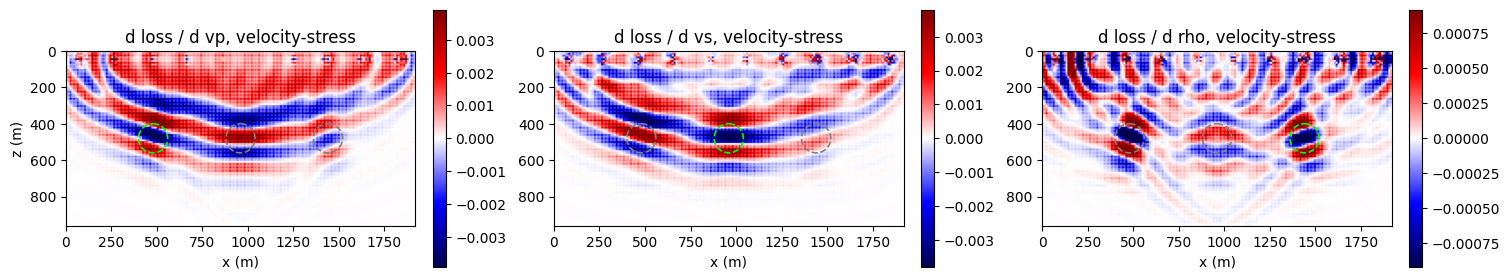

In [7]:
from sweep.sem.equations import ElasticVSSEM2DDeformed

vs_solver = PropSEM(ElasticVSSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                    abcn=20, f_dominant=f0, source_type=['sxx', 'szz'],
                    receiver_type=['vx', 'vz'], impl=impl, device=device)
print('memory strategy:', vs_solver.memory_strategy)
with torch.no_grad():
    observed_vs = vs_solver(wavelet, sources, receivers, models=true)
_, grads_vs = gradient(vs_solver, obs=observed_vs)
for name, a, b in zip(('vp', 'vs', 'rho'), grads, grads_vs):
    cos = torch.nn.functional.cosine_similarity(a.flatten(), b.flatten(), dim=0)
    print(f'{name:3s}: cosine with the displacement class {float(cos):.4f}')
show(grads_vs, ', velocity-stress')

The gradients are those of the displacement class to a cosine of 0.9997 or more: the two
classes discretize the same equations.

## 5. What to use when

- **Many shots, an equation with `impl='c'`**: the defaults (`impl=None` on a GPU, no
  `memory=`).
- **An equation without CUDA kernels, or the CPU**: eager with its default
  `Ckpt(chunks=8)`.
- **Less memory with boundary saving**: `bs_band_mode='rim'` on the acoustic equations, and
  `storage_dtype='bf16'` with `bs_store_dtype_elem='int8'` on the elastic one.
- **Second derivatives** (`create_graph=True`, Hessian-vector products): eager with `Full()`.
- **Biot and the attenuating classes**: `Full()` or `Ckpt`; boundary saving is refused,
  since their drag and attenuation cannot be stepped back in time.
- **Per-shot models**: `models=[vp_b]` with `vp_b` of shape `(nshots, nz, nx)` gives each
  shot its own model; see [Batched local windows · FWI](../44_sem_batched_local_window_fwi/).

Next: [SEM fluid-solid · water over an elastic sea floor](../55_sem_fluid_solid/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="54_sem_gradients_and_memory.ipynb" download><code>54_sem_gradients_and_memory.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/54_sem_gradients_and_memory.ipynb">view on GitHub</a></p>